# Piece interactions with shapiq

Shapley values (see `example.ipynb`) give each piece a single number, and split the credit for
what pieces achieve *together* evenly between them. With [shapiq](https://github.com/mmschlk/shapiq)
chessplainer also computes **Shapley interactions** between pairs of pieces: whether two pieces are
worth more for White together than separately (positive) or partly redundant (negative).

Requires the optional dependency (Python >= 3.12): `pip install "chessplainer[shapiq]"`, plus a
Stockfish binary.

The explained output is White's **expected score** (win + draw / 2), from Stockfish's evaluation.

In [1]:
import chess
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from chessplainer import ChessExplainer, EngineWrapper

plt.rcParams["font.family"] = "DejaVu Sans"
plt.style.use("default")

/Users/francesco/github/chessplainer/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
FIT_LIMIT_KWARGS = dict(depth=20)
PREDICT_LIMIT_KWARGS = dict(depth=12)
COLORS = {
    "square light": "#ffffff",
    "square dark": "#aaaaaa",
    "margin": "#000000",
}

## 1. An endgame: exact interactions

With up to 14 pieces (kings excluded) every subset of pieces is evaluated once, so the values are
exact. This position has 5 pieces: 2^5 = 32 Stockfish evaluations.

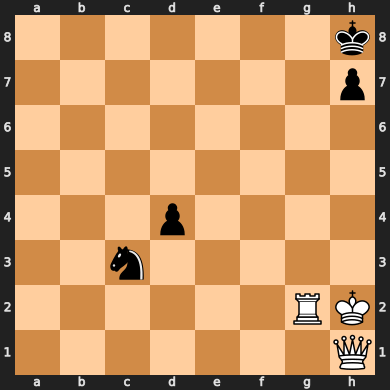

In [3]:
FEN = "7k/7p/8/8/3p4/2n5/6RK/7Q w - - 0 1"
board = chess.Board(FEN)
board

In [4]:
%%time
engine = EngineWrapper(
    path="stockfish",
    fit_limit_kwargs=FIT_LIMIT_KWARGS,
    predict_limit_kwargs=PREDICT_LIMIT_KWARGS,
)
engine.fit([board])

explainer = ChessExplainer(board, engine)
ksii = explainer.explain_interactions(index="k-SII", max_order=2)
print(f"kings only (baseline): {ksii.baseline_value:.3f}")
print(f"full position f(x):    {ksii.baseline_value + explainer.interactions_df_['value'].sum():.3f}")

kings only (baseline): 0.506
full position f(x):    0.998
CPU times: user 92.5 ms, sys: 28.7 ms, total: 121 ms
Wall time: 536 ms


One row per piece (order 1) and per pair of pieces (order 2), sorted by absolute value. The baseline
plus all the values adds up to the evaluation of the full position.

In [5]:
explainer.interactions_df_

,pieces,order,colors,value
8,♖ g2,1,,0.378533
4,♕ h1,1,,0.374950
0,♕ h1 + ♖ g2,2,same,-0.310417
1,♕ h1 + ♞ c3,2,opposite,0.256250
11,♞ c3,1,,-0.109133
5,♖ g2 + ♞ c3,2,opposite,-0.103917
3,♕ h1 + ♟ h7,2,opposite,0.086250
2,♕ h1 + ♟ d4,2,opposite,0.085917
6,♖ g2 + ♟ d4,2,opposite,0.085750
9,♞ c3 + ♟ d4,2,same,-0.082083


The single-piece rows (order 1) are **not** the pieces' Shapley values: they are what is left of
each piece once its pairs are taken out. A piece's total value is its single-piece value plus half
of each pair it belongs to, which for k-SII is exactly its Shapley value (the same number as in
`example.ipynb`). `piece_values_` has these totals, and the board below colors squares by them.

In [6]:
explainer.piece_values_

♕ h1    0.433950
♖ g2    0.243033
♞ c3   -0.106633
♟ d4   -0.044883
♟ h7   -0.033467
Name: value, dtype: float64

How to read the pairs:

- **Negative pair value: redundancy.** If the queen and the rook each win on their own, having both
  adds little, so their pair value is negative: part of each piece's individual value is "shared".
- **Positive pair value: synergy or dependence.** The two pieces matter more together than apart,
  e.g. a defender that only matters when the attacker it stops is on the board.

On the board, squares are colored by each piece's own (first-order) value and arrows connect the
strongest pairs (red: positive, blue: negative). Squares and arrows use separate color scales, and
the arrow direction carries no meaning, since interactions are symmetric. Pairs on adjacent squares
get short arrows that can hide under the pieces: the table above always has every pair.

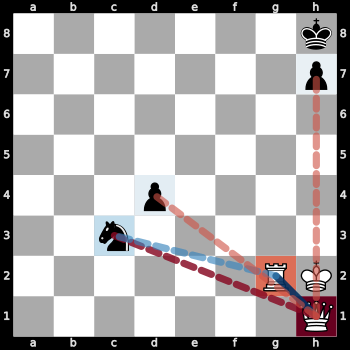

In [7]:
explainer.interactions_to_svg(top_k=5, colors=COLORS)

The same values as an interaction network (shapiq): node size is the first-order value, edge width
the pairwise one.

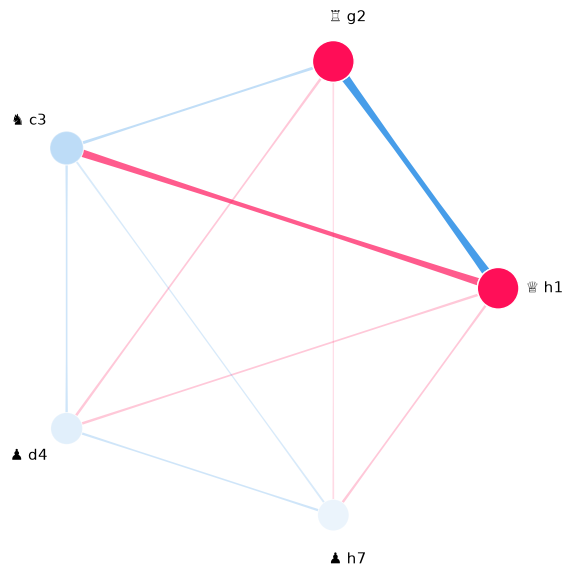

In [8]:
ksii.plot_network(feature_names=explainer.game_.player_names, show=False)
plt.show()

## 2. Comparing indices on the same evaluations

Different indices weigh subsets of pieces differently. Shapley values weigh every subset *size*
equally, so near-empty boards weigh a lot. Banzhaf values weigh every *subset* equally, so mostly
mid-sized ones. The single-piece part of k-SII redistributes each pair's value between the two
pieces. All of them reuse the 32 evaluations above: no new Stockfish calls.

In [9]:
sv = explainer.explain_interactions(index="SV", max_order=1)
bv = explainer.explain_interactions(index="BV", max_order=1)
ksii = explainer.explain_interactions(index="k-SII", max_order=2)

names = explainer.game_.player_names
comparison = pd.DataFrame(
    {
        "Shapley": [sv[(i,)] for i in range(len(names))],
        "Banzhaf": [bv[(i,)] for i in range(len(names))],
        "k-SII (order 1)": [ksii[(i,)] for i in range(len(names))],
    },
    index=names,
)
comparison.round(3)

,Shapley,Banzhaf,k-SII (order 1)
♕ h1,0.434,0.444,0.375
♖ g2,0.243,0.251,0.379
♞ c3,-0.107,-0.150,-0.109
♟ d4,-0.045,-0.057,-0.049
♟ h7,-0.033,-0.042,-0.032


Sanity check: shapiq's exact Shapley values against chessplainer's KernelSHAP explanation. With the
default `lichess` model White's expected score is the win probability (output 0), so they match.

In [10]:
explainer.explain()
comparison["KernelSHAP (chessplainer)"] = explainer.values_[0, :, 0]
comparison[["Shapley", "KernelSHAP (chessplainer)"]].round(4)

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  3.43it/s]


,Shapley,KernelSHAP (chessplainer)
♕ h1,0.4340,0.4340
♖ g2,0.2430,0.2430
♞ c3,-0.1066,-0.1066
♟ d4,-0.0449,-0.0449
♟ h7,-0.0335,-0.0335


## 3. Same-color and opposite-color pairs

The `colors` column separates two kinds of pairs:

- **Same color**: cooperation (positive, e.g. a battery or mutual protection) or redundancy
  (negative, e.g. a queen and a rook that each win on their own).
- **Opposite colors**: attack and defense. Since values are always from White's point of view,
  a positive value means the white piece overcomes the black one (here the queen matters a lot
  only because the knight would otherwise hold the position), a negative value that the black
  piece neutralizes the white one (e.g. a blockader or a defender).

On the board, same-color pairs are solid arrows and opposite-color pairs are dashed. `pairs="same"`
or `pairs="opposite"` shows only one kind.

In [11]:
df = explainer.interactions_df_
df[df["colors"] == "opposite"]

,pieces,order,colors,value
1,♕ h1 + ♞ c3,2,opposite,0.256250
5,♖ g2 + ♞ c3,2,opposite,-0.103917
3,♕ h1 + ♟ h7,2,opposite,0.086250
2,♕ h1 + ♟ d4,2,opposite,0.085917
6,♖ g2 + ♟ d4,2,opposite,0.085750
7,♖ g2 + ♟ h7,2,opposite,0.057583


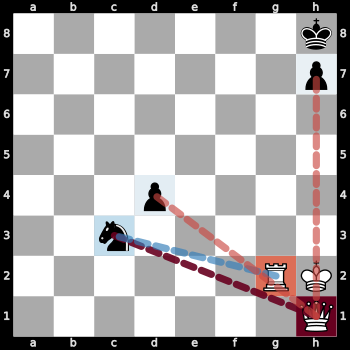

In [12]:
explainer.interactions_to_svg(top_k=4, pairs="opposite", colors=COLORS)

## 4. Explaining the evaluation in pawns

Win probabilities saturate near 0 and 1: once one piece decides the game, the others add little,
which shows up as redundancy (negative pairs). With `output="pawns"` the explained value is White's
evaluation in pawns, clipped to `[-clip, clip]` (mates count as `±clip`), which saturates less.
It is not linear in material either (Stockfish's centipawns are calibrated on win chances, and
lopsided reduced positions often reach the clip), so treat it as a second view, not a fix.
This needs new evaluations (32 here), since the explained output changes.

In [13]:
explainer.explain_interactions(index="k-SII", max_order=2, output="pawns", clip=10)
explainer.interactions_df_.head(10)

,pieces,order,colors,value
4,♕ h1,1,,5.504167
8,♖ g2,1,,5.420000
1,♕ h1 + ♞ c3,2,opposite,3.814167
0,♕ h1 + ♖ g2,2,same,-2.227500
11,♞ c3,1,,-1.705000
6,♖ g2 + ♟ d4,2,opposite,1.599167
3,♕ h1 + ♟ h7,2,opposite,1.547500
12,♟ d4 + ♟ h7,2,same,-1.490833
9,♞ c3 + ♟ d4,2,same,-1.464167
2,♕ h1 + ♟ d4,2,opposite,1.455833


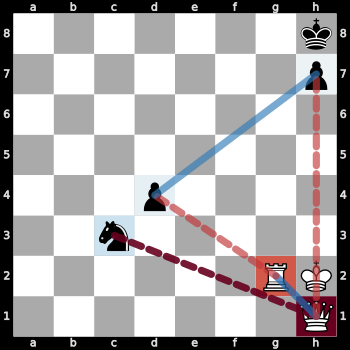

In [14]:
explainer.interactions_to_svg(top_k=5, colors=COLORS)

In [15]:
engine.close()

## 5. A middlegame: approximated interactions

With 28 pieces there are 2^28 subsets, so values are approximated by sampling. Single-piece values
are stable with a few thousand evaluations; pairwise values (378 of them) are not. On this position,
two runs with different seeds agreed with correlation ~0 at 2048 evaluations, 0.5 at 8192 and 0.8 at
32768, which is the default budget for interactions. A shallower search keeps this to about a minute
(depth 8; each extra depth level costs time).

In middlegames the strongest values are mostly about **material** (queens, rooks, and matching pairs
of them), a known property of removal-based explanations: the most interesting pairs show up in
endgames and tactical positions. These matching-material pairs remain with `output="pawns"` too: in the full position the two queens are almost exactly additive, but not on the sparse, lopsided boards that the explanation averages over.

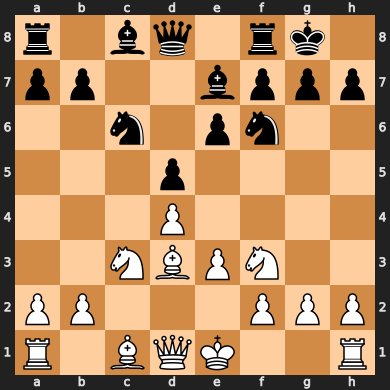

In [16]:
FEN_MIDDLEGAME = "r1bq1rk1/pp2bppp/2n1pn2/3p4/3P4/2NBPN2/PP3PPP/R1BQK2R w KQ - 0 9"
board_mid = chess.Board(FEN_MIDDLEGAME)
board_mid

In [17]:
%%time
engine_mid = EngineWrapper(path="stockfish", predict_limit_kwargs=dict(depth=8))
engine_mid.fit([board_mid])

explainer_mid = ChessExplainer(board_mid, engine_mid)
ksii_mid = explainer_mid.explain_interactions(index="k-SII", max_order=2, random_state=0)
explainer_mid.interactions_df_.head(15)

CPU times: user 28.4 s, sys: 2.24 s, total: 30.6 s
Wall time: 1min 19s


,pieces,order,colors,value
80,♕ d1,1,,0.363843
404,♛ d8,1,,-0.347322
27,♖ a1,1,,0.239350
405,♜ f8,1,,-0.229981
105,♖ h1,1,,0.222795
399,♜ a8,1,,-0.209365
129,♙ a2,1,,0.196266
174,♙ f2,1,,0.193539
152,♙ b2,1,,0.186126
195,♙ g2,1,,0.127169


The single-piece rows can even have the opposite sign of a piece's total value. A lone knight or
bishop cannot win (king and knight against king is a draw), so a minor piece's value lives almost
entirely in its pairs with other pieces: many small positive pairs, none of them in the top rows,
and a negative single-piece row. A pawn is the reverse: alone on an empty board it promotes, so its
single-piece row is large, and its pairs with the pieces that stop it are negative. The totals:

In [18]:
explainer_mid.piece_values_.head(15)

♕ d1    0.373843
♛ d8   -0.360322
♖ h1    0.222795
♜ f8   -0.219981
♖ a1    0.219850
♜ a8   -0.199365
♗ d3    0.152959
♝ e7   -0.149598
♞ f6   -0.148425
♞ c6   -0.139320
♗ c1    0.133849
♘ f3    0.133809
♘ c3    0.130219
♝ c8   -0.124891
♟ g7   -0.074222
Name: value, dtype: float64

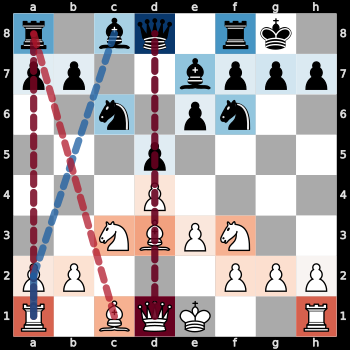

In [19]:
explainer_mid.interactions_to_svg(top_k=5, colors=COLORS)

In [20]:
engine_mid.close()